In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import torch


device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


class CRNetwork(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self, n_ST=2, noise=1e-6, int_thresh=-28.0,
        max_power=10e-3, steps_per_run=100, dtype=np.float32, seed=None,
        interference_reference_w=1.0, error_variance=0.1, hist_len = 1,
        reward_mode="paper", alpha=0.2,beta=10.0):
        super().__init__()

        if not isinstance(n_ST, (int, np.integer)) or n_ST < 1:
            raise ValueError("n_ST must be a positive integer.")
        if not isinstance(steps_per_run, (int, np.integer)) or steps_per_run < 1:
            raise ValueError("steps_per_run must be a positive integer.")
        if not np.issubdtype(np.dtype(dtype), np.floating):
            raise ValueError("Use a floating-point observation dtype.")

        parameters = (noise, int_thresh, max_power, interference_reference_w)
        if not np.all(np.isfinite(parameters)):
            raise ValueError("Environment parameters must be finite.")
        if noise <= 0 or max_power <= 0 or interference_reference_w <= 0:
            raise ValueError("Noise, power budget, and interference reference must be positive.")
        if not np.isfinite(error_variance) or error_variance < 0:
            raise ValueError("error_variance must be finite and nonnegative.")
        if not np.isfinite(alpha) or not 0 <= alpha <= 1:
            raise ValueError("alpha must be between 0 and 1.")
        if not np.isfinite(beta) or beta < 0:
            raise ValueError("beta must be finite and nonnegative.")

        self.k = int(n_ST)
        self.N0 = float(noise)
        self.Pmax = float(max_power)
        self.Ith = float(10**(int_thresh / 10))

        if not np.isfinite(self.Ith) or self.Ith <= 0:
            raise ValueError("Converted interference threshold must be finite and positive.")

        self.max_steps = int(steps_per_run)
        self.dtype = np.dtype(dtype)

        self.hist_len = int(hist_len)
        assert self.hist_len >= 1
        self.obs_dim = (self.hist_len + 1) * self.k + 1
        self.action_dim = self.k

        self.error_variance = float(error_variance)
        self.beta = float(beta)
        self.alpha = float(alpha)

        self.reward_mode = "paper" if reward_mode == "paper" else "custom"

        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(self.obs_dim,),
            dtype=self.dtype
        )
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(self.k,),
            dtype=self.dtype
        )

        # Random number generator
        self.np_random = np.random.default_rng(seed)
        self.step_count = 0
        self._needs_reset = True

    def get_channel_gain(self, update=True):

        # Update complex channel coefficients only when requested
        if update:
           # Noisy estimate
            w_p = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)
            w_s = (self.np_random.standard_normal(self.k)+ 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

            # Temporally correlated ST-PR channels
            self.hint = ((1 - self.alpha) * self.hint + np.sqrt(2 * self.alpha - self.alpha**2) * w_p)
            self.hsr = ((1 - self.alpha) * self.hsr + np.sqrt(2 * self.alpha - self.alpha**2) * w_s)
        # Actual channel power gains
        g_pr_actual = np.abs(self.hint)**2
        g_sr = np.abs(self.hsr)**2
        # Imperfect CSI on ST-PR links only
        error = np.sqrt(self.error_variance / 2) * (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k))

        hpr_est = self.hint + error
        gpr_est = np.abs(hpr_est)**2
        self.hpr_est = hpr_est

        return g_pr_actual, gpr_est, g_sr

    def _observation(self):
        # return np.concatenate(
        #     [self.hint_est, self.P_prev, [self.r_prev]]
        # ).astype(self.dtype)
        return np.concatenate([self.est_hist.ravel(), self.P_prev, [self.r_prev]]).astype(self.dtype)

    def reset(self, *, seed=None, options=None):

        super().reset(seed=seed)

        self.step_count = 0
        self.P_prev = np.zeros(self.k)
        self.r_prev = 0.0

        # Initialize complex channel coefficients
        self.hint = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        self.hsr = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        # Initial channel gains and imperfect CSI
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=False))
        self.est_hist = np.tile(self.hint_est, (self.hist_len, 1))   # pad history with the current estimate

        self._needs_reset = False

        return self._observation(), {}

    def step(self, action):

        if self._needs_reset:
            raise RuntimeError("Call reset() before stepping or after an episode ends.")

        action = np.asarray(action, dtype=np.float64)

        if action.shape != (self.k,) or not np.all(np.isfinite(action)):
            raise ValueError(f"Expected a finite action with shape ({self.k},).")

        raw_action = np.clip(action, -1.0, 1.0)

        # Action-to-power mapping
        fractions = (raw_action + 1.0) / 2.0
        powers = fractions * self.Pmax

        # Capacity using actual desired channel gains
        signal_power = powers * self.g_sr
        snr = signal_power / self.N0
        capacity = np.log2(1.0 + snr)

        # Actual primary interference
        interference = float(np.sum(powers * self.g_pr_actual))

        normalized_violation = max(
            0.0,
            (interference - self.Ith) / self.Ith
        )

        power_ok = bool(
            np.all(powers >= 0) and np.all(powers <= self.Pmax)
        )

        feasible = bool(interference <= self.Ith and power_ok)

        # Reward calculation
        if self.reward_mode == "paper":
            reward = float(capacity.sum()) if feasible else -interference
        else:
            reward = float(capacity.sum()) - self.beta * normalized_violation

        info = {
            "capacity": capacity.copy(),
            "snr": snr.copy(),
            "interference": interference,
            "constraints_satisfied": feasible,
            "allocation_fractions": fractions.copy(),
            "transmit_powers": powers.copy(),
            "actual_interference_gains": self.g_pr_actual.copy(),
            "desired_gains": self.g_sr.copy(),
            "estimated_interference": float(np.sum(powers * self.hint_est)),
            "normalized_excess": float(normalized_violation),
            "penalty": float(self.beta * normalized_violation),
            "actual_violation": bool(interference > self.Ith),
            "estimated_violation": bool(np.sum(powers * self.hint_est) > self.Ith),
        }
        # Store previous action and reward
        self.P_prev = powers.copy()
        self.r_prev = reward

        self.step_count += 1

        terminated = False
        truncated = bool(self.step_count >= self.max_steps)

        # Generate next channel realization for the next observation
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=True))
        self.est_hist = np.vstack([self.hint_est, self.est_hist[:-1]])  # newest first

        self._needs_reset = truncated

        return self._observation(), reward, terminated, truncated, info


In [2]:
class ReplayBuffer:
  def __init__(self, state_dim, action_dim, max_size):
    self.mem_size = max_size
    self.mem_cntr = 0
    self.state_memory = np.zeros((self.mem_size, state_dim), dtype = np.float32)
    self.next_state_memory = np.zeros((self.mem_size, state_dim), dtype = np.float32)
    self.action_memory = np.zeros((self.mem_size, action_dim), dtype = np.float32)
    self.reward_memory = np.zeros(self.mem_size, dtype = np.float32)
    self.terminal_memory = np.zeros(self.mem_size, dtype = np.uint8)

  def store_transition(self, state, action, reward, next_state, done):
    index = self.mem_cntr % self.mem_size
    self.state_memory[index] = state
    self.action_memory[index] = action
    self.reward_memory[index] = reward
    self.next_state_memory[index] = next_state
    self.terminal_memory[index] = done

    self.mem_cntr += 1

  def sample_batch(self, batch_size = 256):
    max_mem = min(self.mem_cntr, self.mem_size)
    batch = np.random.choice(max_mem, batch_size)
    states = self.state_memory[batch]
    actions = self.action_memory[batch]
    rewards = self.reward_memory[batch]
    states_ = self.next_state_memory[batch]
    dones = self.terminal_memory[batch]
    return states, actions, rewards, states_, dones

## Networks

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class Actor(nn.Module):
  def __init__(self, state_dim, action_dim, action_max):
    super(Actor, self).__init__()
    self.action_max = action_max
    self.device = device

    self.linear1 = nn.Linear(state_dim, 64)
    self.linear2 = nn.Linear(64, 64)
    self.linear3 = nn.Linear(64, action_dim)

  def forward(self, state):
    x = F.relu(self.linear1(state))
    x = F.relu(self.linear2(x))
    x = torch.tanh(self.linear3(x))

    action_max = torch.as_tensor(
        self.action_max,
        dtype=x.dtype,
        device=x.device,
    )

    return x * action_max

class Critic(nn.Module):
  def __init__(self, state_dim, action_dim, trainable = True):
    super(Critic, self).__init__()
    self.device = device
    self.W_s = nn.Parameter(torch.randn(state_dim, 64), requires_grad = trainable)
    self.W_a = nn.Parameter(torch.randn(action_dim, 64), requires_grad = trainable)
    self.b1 = nn.Parameter(torch.randn(1, 64), requires_grad = trainable)
    self.linear1 = nn.Linear(64, 64)
    self.linear2 = nn.Linear(64, 1)

  def forward(self, state, action):
    x = F.relu(torch.matmul(state, self.W_s) + torch.matmul(action, self.W_a) + self.b1)
    x = F.relu(self.linear1(x))
    x = self.linear2(x)
    return x

In [4]:
def prep_obs(obs, p_max, n):
    """Scale the previous-power block of the state to [0, 1] so it is visible to the network."""
    o = obs.copy()
    o[n:2 * n] /= p_max
    return o

## SAC Class

In [5]:


from copy import deepcopy
from pathlib import Path
import math
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.distributions import Normal


class SACActor(nn.Module):
    def __init__(self, state_dim, action_dim, action_max):
        super().__init__()
        self.linear1 = nn.Linear(state_dim, 64)
        self.linear2 = nn.Linear(64, 64)
        self.mean_head = nn.Linear(64, action_dim)
        self.log_std_head = nn.Linear(64, action_dim)
        self.register_buffer("action_scale", torch.as_tensor(
            np.broadcast_to(np.asarray(action_max, dtype=np.float32),
                            (action_dim,)).copy()))

    def forward(self, state):
        x = F.relu(self.linear1(state))
        x = F.relu(self.linear2(x))
        mean = self.mean_head(x)
        log_std = self.log_std_head(x).clamp(-20.0, 2.0)
        return mean, log_std

    def sample(self, state):
        mean, log_std = self.forward(state)
        distribution = Normal(mean, log_std.exp())

        raw_action = distribution.rsample()
        action = torch.tanh(raw_action) * self.action_scale


        log_tanh_jacobian = 2 * (
            math.log(2.0) - raw_action - F.softplus(-2 * raw_action)
        )
        logprob = (distribution.log_prob(raw_action)
                   - log_tanh_jacobian - self.action_scale.log())
        return action, logprob.sum(dim=-1, keepdim=True)


class SAC_Agent:
    def __init__(self, alpha, beta, state_dim, tau, action_max,
                 gamma=0.99, action_dim=2, max_size=1_000_000,
                 batch_size=256, seed=0, device=None, entropy_coef=0.2):

        self.device = torch.device(device if device is not None else
                                   ("cuda" if torch.cuda.is_available() else "cpu"))
        if not 0 <= gamma <= 1 or not 0 < tau <= 1:
            raise ValueError("Require gamma in [0, 1] and tau in (0, 1].")
        if batch_size < 1 or max_size < batch_size:
            raise ValueError("Require max_size >= batch_size >= 1.")
        if not np.isfinite(entropy_coef) or entropy_coef < 0:
            raise ValueError("entropy_coef must be finite and nonnegative.")

        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.entropy_coef = float(entropy_coef)
        self.high = np.broadcast_to(np.asarray(action_max, dtype=np.float32),
                                    (action_dim,)).copy()
        if not np.all(np.isfinite(self.high)) or np.any(self.high <= 0):
            raise ValueError("action_max must contain positive raw-action bounds.")
        self.low = -self.high

        torch.manual_seed(seed)
        np.random.seed(seed)
        self.memory = ReplayBuffer(state_dim, action_dim, max_size)
        if not np.issubdtype(self.memory.action_memory.dtype, np.floating):
            raise TypeError("ReplayBuffer.action_memory must be floating point.")

        self.actor = SACActor(state_dim, action_dim, self.high).to(self.device)
        self.critic_1 = Critic(state_dim, action_dim).to(self.device)
        self.critic_2 = Critic(state_dim, action_dim).to(self.device)
        self.target_critic_1 = deepcopy(self.critic_1).requires_grad_(False)
        self.target_critic_2 = deepcopy(self.critic_2).requires_grad_(False)
        for network in (self.actor, self.critic_1, self.critic_2,
                        self.target_critic_1, self.target_critic_2):
            network.device = self.device
        self.target_critic_1.eval()
        self.target_critic_2.eval()

        self.actor.optimizer = torch.optim.Adam(self.actor.parameters(), lr=alpha)
        self.critic_1.optimizer = torch.optim.Adam(self.critic_1.parameters(), lr=beta)
        self.critic_2.optimizer = torch.optim.Adam(self.critic_2.parameters(), lr=beta)

    @torch.no_grad()
    def choose_action(self, s, *, deterministic=False):
        """Stochastic for training; tanh(mean) for deterministic evaluation."""
        s = np.asarray(s, dtype=np.float32)
        if s.shape != (self.state_dim,) or not np.all(np.isfinite(s)):
            raise ValueError(f"Expected a finite observation of shape ({self.state_dim},).")
        state = torch.as_tensor(s, device=self.device).unsqueeze(0)
        was_training = self.actor.training
        self.actor.eval()
        if deterministic:
            mean, _ = self.actor(state)
            action = torch.tanh(mean) * self.actor.action_scale
        else:
            action, _ = self.actor.sample(state)
        self.actor.train(was_training)
        return action.cpu().numpy().reshape(self.action_dim).astype(np.float32)

    def remember(self, state, action, reward, next_state, done):

        self.memory.store_transition(state, action, float(reward), next_state, bool(done))

    def learn(self):
        if self.memory.mem_cntr < self.batch_size:
            return None

        states, actions, rewards, next_states, done = self.memory.sample_batch(self.batch_size)
        states = torch.as_tensor(states, dtype=torch.float32, device=self.device)
        actions = torch.as_tensor(actions, dtype=torch.float32, device=self.device)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=self.device).reshape(-1, 1)
        next_states = torch.as_tensor(next_states, dtype=torch.float32, device=self.device)
        done = torch.as_tensor(done, dtype=torch.float32, device=self.device).reshape(-1, 1)
        self.actor.train()
        self.critic_1.train()
        self.critic_2.train()

        # target Q
        with torch.no_grad():
            next_actions, next_logprob = self.actor.sample(next_states)
            next_q1 = self.target_critic_1(next_states, next_actions).reshape(-1, 1)
            next_q2 = self.target_critic_2(next_states, next_actions).reshape(-1, 1)
            next_value = torch.minimum(next_q1, next_q2) - self.entropy_coef * next_logprob
            target_q = rewards + self.gamma * (1 - done) * next_value

        # update critics
        q1 = self.critic_1(states, actions).reshape(-1, 1)
        q2 = self.critic_2(states, actions).reshape(-1, 1)
        critic_loss = F.mse_loss(q1, target_q) + F.mse_loss(q2, target_q)
        self.critic_1.optimizer.zero_grad()
        self.critic_2.optimizer.zero_grad()
        critic_loss.backward()
        self.critic_1.optimizer.step()
        self.critic_2.optimizer.step()

        #  update actor using new samples
        self.critic_1.requires_grad_(False)
        self.critic_2.requires_grad_(False)
        new_actions, logprob = self.actor.sample(states)
        new_q1 = self.critic_1(states, new_actions).reshape(-1, 1)
        new_q2 = self.critic_2(states, new_actions).reshape(-1, 1)
        actor_loss = (self.entropy_coef * logprob - torch.minimum(new_q1, new_q2)).mean()
        self.actor.optimizer.zero_grad()
        actor_loss.backward()
        self.actor.optimizer.step()
        self.critic_1.requires_grad_(True)
        self.critic_2.requires_grad_(True)

        # critics are soft-updated
        self.update_network_parameters()
        return [actor_loss.item(), critic_loss.item()]

    @torch.no_grad()
    def update_network_parameters(self, tau=None):
        tau = self.tau if tau is None else tau
        if not 0 <= tau <= 1:
            raise ValueError("tau must lie in [0, 1].")
        for online, target in ((self.critic_1, self.target_critic_1),
                               (self.critic_2, self.target_critic_2)):
            for parameter, target_parameter in zip(online.parameters(), target.parameters()):
                target_parameter.mul_(1 - tau).add_(parameter, alpha=tau)

    def save_models(self, path="sac_models.pt"):
        """Evaluation weights; optimizer states and replay are not included."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        names = ("actor", "critic_1", "critic_2", "target_critic_1", "target_critic_2")
        checkpoint = {name: getattr(self, name).state_dict() for name in names}
        checkpoint.update(state_dim=self.state_dim, action_dim=self.action_dim,
                          high=self.high.tolist(), entropy_coef=self.entropy_coef)
        torch.save(checkpoint, path)

    def load_models(self, path="sac_models.pt"):
        checkpoint = torch.load(path, map_location=self.device, weights_only=True)
        if (checkpoint["state_dim"] != self.state_dim
                or checkpoint["action_dim"] != self.action_dim
                or not np.allclose(checkpoint["high"], self.high)):
            raise ValueError("Checkpoint dimensions or raw-action bounds do not match.")
        for name in ("actor", "critic_1", "critic_2", "target_critic_1", "target_critic_2"):
            network = getattr(self, name)
            network.load_state_dict(checkpoint[name])
            network.eval()
        self.entropy_coef = float(checkpoint["entropy_coef"])


In [6]:
from google.colab import files
files.upload();

Saving utils.py to utils.py



========== SAC ENVIRONMENT CONFIGURATION ==========
Secondary pairs       : 2
State dimension       : 5
Action dimension      : 2
Maximum power         : 10.00 mW per SU
Noise power           : 1.000000e-06 W
Interference threshold: 2.00 dBm
Threshold in watts    : 1.584893e-03 W
Training steps        : 100000
Discount factor       : 0.9
Target update tau     : 0.005
Actor learning rate   : 0.001
Critic learning rate  : 0.002
Replay buffer size    : 1000000
Batch size            : 256
Warm-up steps         : 1000
Entropy coefficient   : 0.2

Forced full power violates 98.33% of steps.
Training device: cpu
Episode    1/1000 | Steps    100 | Reward -29.6099 | Capacity  22.2213 | Interference    9.904 dBm | Violations  95.00% | Recent reward -29.6099 | Recent capacity  22.2213
Episode   11/1000 | Steps   1100 | Reward  -7.6461 | Capacity  18.1962 | Interference    7.200 dBm | Violations  54.00% | Recent reward -27.7801 | Recent capacity  21.5379
Episode   21/1000 | Steps   2100 | Reward 

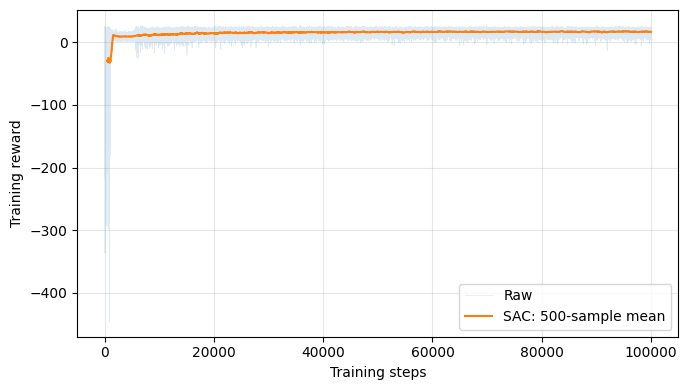

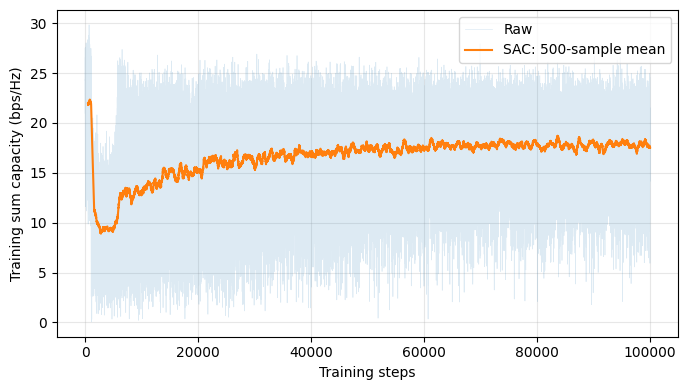

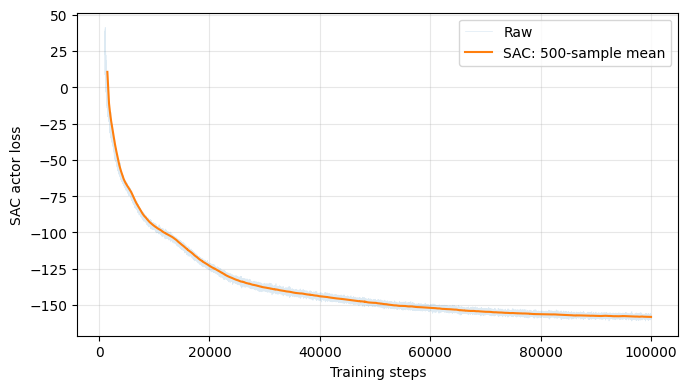

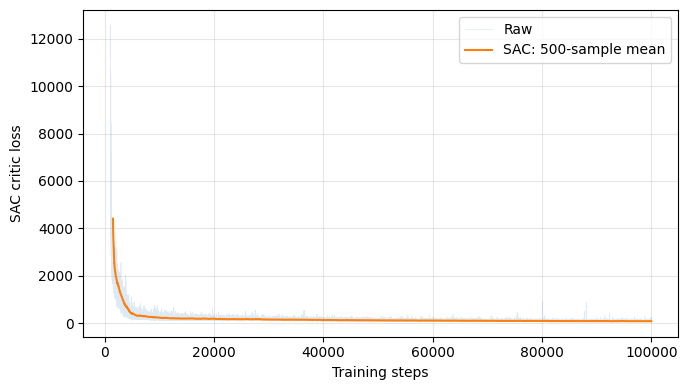

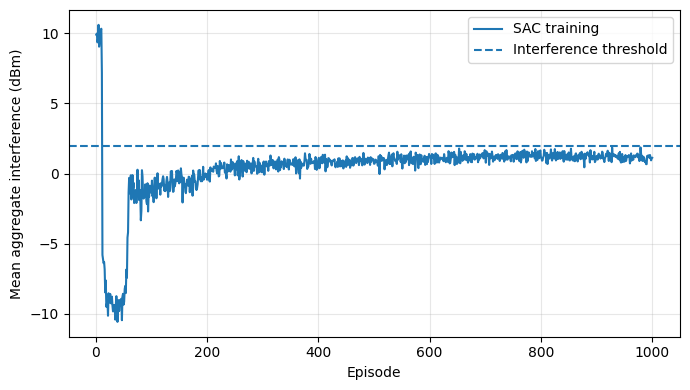

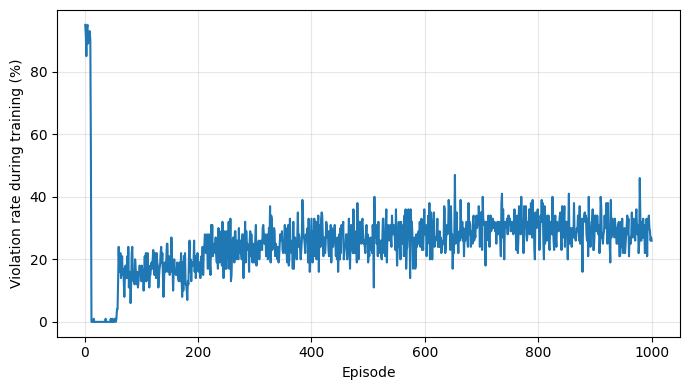

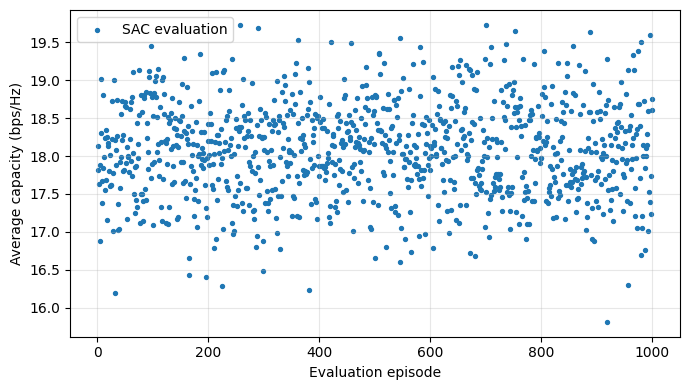

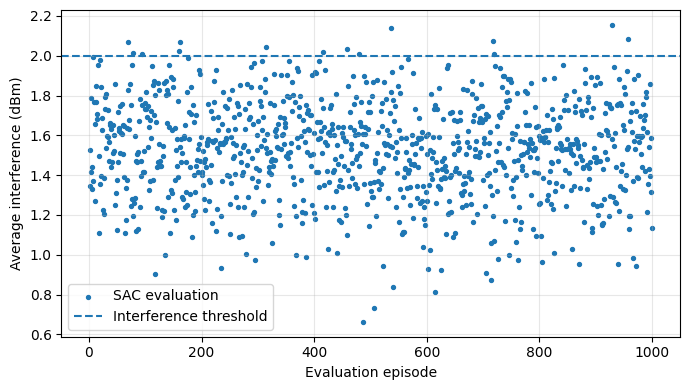

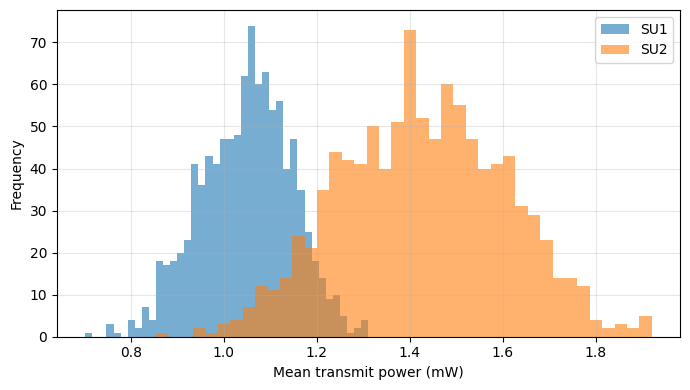

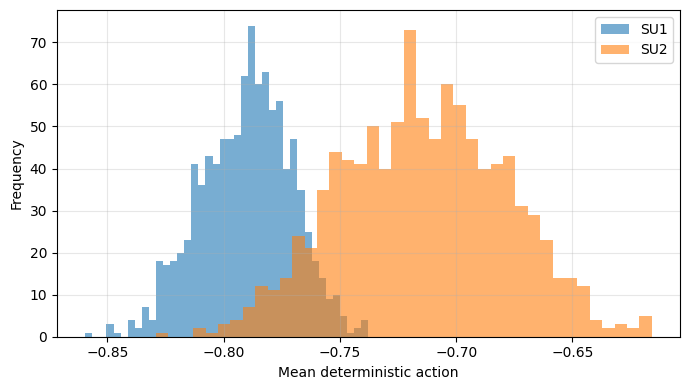


                  SAC RESULTS

TRAINING
Training steps: 100000
Training time: 806.13 seconds
Mean reward: 15.1885
Mean capacity: 16.5520 bps/Hz
Mean interference: 0.9042 dBm
Violation rate: 25.28%
Mean total power: 2.2959 mW

SAC CONFIGURATION
Gamma: 0.9
Tau: 0.005
Actor learning rate: 0.001
Critic learning rate: 0.002
Replay buffer size: 1000000
Batch size: 256
Warm-up steps: 1000
Entropy coefficient: 0.2

EVALUATION
Mean reward: 17.0732
Mean capacity: 18.0803 +/- 0.6170 bps/Hz
Mean interference: 1.5331 dBm
Interference threshold: 2.00 dBm
Violation rate: 36.62%
Constraint satisfaction: 63.38%
SU1 mean power: 1.0486 mW
SU1 mean action: -0.7903
SU2 mean power: 1.4290 mW
SU2 mean action: -0.7142
Execution time: 0.2033 ms/action

Saved results to:
/content/sac_results


In [7]:

from pathlib import Path
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from utils import *


# ============================================================
# 1. ENVIRONMENT AND EXPERIMENT CONFIGURATION
# ============================================================

N_ST = 2

MAX_POWER_MW = 10.0
NOISE_POWER_MW = 1e-3
ITH_DBM = 2.0

MAX_POWER = MAX_POWER_MW * 1e-3
N0 = NOISE_POWER_MW * 1e-3
ITH_DBW = ITH_DBM - 30.0

STEPS_PER_RUN = 100

NUM_EPISODES = 1000
TOTAL_TRAINING_STEPS = NUM_EPISODES * STEPS_PER_RUN

# SAC hyperparameters
ACTOR_LR = 1e-3
CRITIC_LR = 2e-3

GAMMA = 0.9
TAU = 0.005

MAX_SIZE = 1_000_000
BATCH_SIZE = 256

WARMUP_STEPS = 1000

# SAC fixed entropy temperature
ENTROPY_COEF = 0.2

SMOOTH_WINDOW = 500

EVAL_EPISODES = 1000
EVAL_SEED_OFFSET = 100_000

seed = 0

OUTPUT_DIR = Path("sac_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. UNIT CONVERSION AND POWER HELPER
# ============================================================

def watts_to_dbm(w):

    w = np.asarray(w, dtype=np.float64)

    with np.errstate(divide="ignore"):
        return np.where(
            w > 0,
            10.0 * np.log10(w / 1e-3),
            -np.inf
        )


def step_powers_w(info, action, env):

    if "transmit_powers" in info:

        return np.asarray(
            info["transmit_powers"],
            dtype=np.float64
        )

    return (
        (np.clip(
            np.asarray(action, dtype=np.float64),
            -1.0,
            1.0
        ) + 1.0) / 2.0
    ) * env.Pmax


# ============================================================
# 3. RANDOM SEEDS
# ============================================================

torch.manual_seed(seed)
np.random.seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ============================================================
# 4. ENVIRONMENT
# ============================================================

env = CRNetwork(
    n_ST=N_ST,
    noise=N0,
    int_thresh=ITH_DBW,
    max_power=MAX_POWER,
    steps_per_run=STEPS_PER_RUN,
    dtype=np.float32,
    seed=seed,
    alpha=0.2,
    reward_mode = "custom"
)


# ============================================================
# 5. VALIDATE PHYSICAL PARAMETERS
# ============================================================

expected_ith_w = 10 ** (ITH_DBM / 10.0) * 1e-3

if not np.isclose(env.Ith, expected_ith_w, rtol=1e-6):

    raise ValueError(
        f"Threshold is {env.Ith:g} W, "
        f"but {ITH_DBM} dBm should be "
        f"{expected_ith_w:g} W."
    )

STATE_DIM = env.observation_space.shape[0]
ACTION_DIM = env.action_space.shape[0]

assert STATE_DIM == 5, (
    f"Expected 5-dimensional state, got {STATE_DIM}"
)

assert ACTION_DIM == 2, (
    f"Expected 2-dimensional action, got {ACTION_DIM}"
)

assert MAX_SIZE >= BATCH_SIZE

print("\n========== SAC ENVIRONMENT CONFIGURATION ==========")

print(f"Secondary pairs       : {N_ST}")
print(f"State dimension       : {STATE_DIM}")
print(f"Action dimension      : {ACTION_DIM}")

print(f"Maximum power         : {MAX_POWER_MW:.2f} mW per SU")
print(f"Noise power           : {N0:.6e} W")

print(f"Interference threshold: {ITH_DBM:.2f} dBm")
print(f"Threshold in watts    : {env.Ith:.6e} W")

print(f"Training steps        : {TOTAL_TRAINING_STEPS}")

print(f"Discount factor       : {GAMMA}")
print(f"Target update tau     : {TAU}")

print(f"Actor learning rate   : {ACTOR_LR}")
print(f"Critic learning rate  : {CRITIC_LR}")

print(f"Replay buffer size    : {MAX_SIZE}")
print(f"Batch size            : {BATCH_SIZE}")

print(f"Warm-up steps         : {WARMUP_STEPS}")
print(f"Entropy coefficient   : {ENTROPY_COEF}")

print("====================================================\n")


# ============================================================
# 6. FORCED FULL-POWER CONSTRAINT CHECK
# ============================================================

def forced_full_power_check(env, episodes=3, seed0=50_000):

    violated = 0
    total = 0

    for e in range(episodes):

        env.reset(seed=seed0 + e)

        for _ in range(STEPS_PER_RUN):

            action = np.ones(
                env.action_space.shape,
                dtype=np.float32
            )

            _, _, terminated, truncated, info = env.step(
                action
            )

            interference_w = float(
                info["interference"]
            )

            violated += int(
                interference_w > env.Ith
            )

            total += 1

            if terminated or truncated:
                break

    return violated / max(total, 1)


full_power_violations = forced_full_power_check(env)

print(
    f"Forced full power violates "
    f"{100 * full_power_violations:.2f}% of steps."
)

if full_power_violations < 0.5:

    print(
        "WARNING: The interference constraint may not be binding. "
        "Check the channel gains and physical units."
    )


# ============================================================
# 7. INITIALIZE SAC AGENT
# ============================================================

sac_agent = SAC_Agent(
    alpha=ACTOR_LR,
    beta=CRITIC_LR,
    state_dim=STATE_DIM,
    tau=TAU,
    action_max=env.action_space.high,
    gamma=GAMMA,
    action_dim=ACTION_DIM,
    max_size=MAX_SIZE,
    batch_size=BATCH_SIZE,
    seed=seed,
    entropy_coef=ENTROPY_COEF
)

training_device = sac_agent.device

print("Training device:", training_device)


# ============================================================
# 8. HISTORY ARRAYS
# ============================================================

step_numbers = []
step_rewards = []
step_capacities = []

step_user_capacities = []
step_snr = []

step_transmit_powers_w = []
step_total_power_w = []

step_violations = []
step_actions = []
step_interference_w = []

episode_interference_w = []
episode_interference_dbm = []
episode_violation_rate = []

episode_reward = []
episode_capacity = []

actor_losses = []
critic_losses = []
loss_steps = []

total_time = 0


# ============================================================
# 9. SAC TRAINING LOOP
# ============================================================

if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

start_time = time.perf_counter()

for episode in range(NUM_EPISODES):

    obs, _ = env.reset(
        seed=seed + episode
    )

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    ).astype(np.float32)

    ep_interference_sum = 0.0
    ep_violations = 0

    ep_reward_sum = 0.0
    ep_capacity_sum = 0.0

    for j in range(STEPS_PER_RUN):

        # --------------------------------------------
        # SELECT ACTION
        # --------------------------------------------

        # Random warm-up actions
        if total_time < WARMUP_STEPS:

            action = np.random.uniform(
                env.action_space.low,
                env.action_space.high
            ).astype(np.float32)

        else:

            # SAC performs its own stochastic exploration.
            # No additional Gaussian exploration noise is added.

            action = sac_agent.choose_action(
                obs,
                deterministic=False
            )

        action = np.asarray(
            action,
            dtype=np.float32
        )

        # --------------------------------------------
        # ENVIRONMENT STEP
        # --------------------------------------------

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        ).astype(np.float32)

        reward = float(reward)

        capacity = np.asarray(
            info["capacity"],
            dtype=np.float64
        )

        powers_w = step_powers_w(
            info,
            action,
            env
        )

        interference_w = float(
            info["interference"]
        )

        violated = bool(
            interference_w > env.Ith
        )

        # --------------------------------------------
        # RECORD STEP STATISTICS
        # --------------------------------------------

        total_time += 1

        step_numbers.append(total_time)
        step_rewards.append(reward)

        step_capacities.append(
            float(capacity.sum())
        )

        step_user_capacities.append(
            capacity.copy()
        )

        step_snr.append(
            2.0 ** capacity - 1.0
        )

        step_transmit_powers_w.append(
            powers_w.copy()
        )

        step_total_power_w.append(
            float(powers_w.sum())
        )

        step_violations.append(
            int(violated)
        )

        step_actions.append(
            action.copy()
        )

        step_interference_w.append(
            interference_w
        )

        # --------------------------------------------
        # EPISODE STATISTICS
        # --------------------------------------------

        ep_interference_sum += interference_w
        ep_violations += int(violated)

        ep_reward_sum += reward
        ep_capacity_sum += float(capacity.sum())

        # --------------------------------------------
        # STORE TRANSITION
        # --------------------------------------------

        # Only true termination is terminal.
        # A time-limit truncation should still bootstrap.

        sac_agent.remember(
            obs,
            action,
            reward,
            next_obs,
            terminated
        )

        obs = next_obs

        # --------------------------------------------
        # SAC UPDATE
        # --------------------------------------------

        if total_time >= WARMUP_STEPS:

            losses = sac_agent.learn()

            if losses is not None:

                actor_losses.append(
                    float(losses[0])
                )

                critic_losses.append(
                    float(losses[1])
                )

                loss_steps.append(total_time)

        if terminated or truncated:
            break

    # --------------------------------------------
    # EPISODE SUMMARIES
    # --------------------------------------------

    steps_done = j + 1

    mean_interference = (
        ep_interference_sum / steps_done
    )

    episode_interference_w.append(
        mean_interference
    )

    episode_interference_dbm.append(
        float(watts_to_dbm(mean_interference))
    )

    episode_violation_rate.append(
        ep_violations / steps_done
    )

    episode_reward.append(
        ep_reward_sum / steps_done
    )

    episode_capacity.append(
        ep_capacity_sum / steps_done
    )

    # --------------------------------------------
    # PRINT EVERY 10 EPISODES
    # Same format as PPO, DDPG and TD3
    # --------------------------------------------

    if episode % 10 == 0 or episode == NUM_EPISODES - 1:

        recent = min(10, len(episode_reward))

        print(
            f"Episode {episode + 1:4d}/{NUM_EPISODES} | "
            f"Steps {total_time:6d} | "
            f"Reward {episode_reward[-1]:8.4f} | "
            f"Capacity {episode_capacity[-1]:8.4f} | "
            f"Interference {episode_interference_dbm[-1]:8.3f} dBm | "
            f"Violations {100 * episode_violation_rate[-1]:6.2f}% | "
            f"Recent reward {np.mean(episode_reward[-recent:]):8.4f} | "
            f"Recent capacity {np.mean(episode_capacity[-recent:]):8.4f}"
        )


if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

training_seconds = time.perf_counter() - start_time


# ============================================================
# 10. DETERMINISTIC EVALUATION
# ============================================================

eval_capacity = []
eval_interference_w = []

eval_violation = []
eval_reward = []

eval_powers = []
eval_actions = []

action_seconds = 0.0
action_calls = 0

sac_agent.actor.eval()
sac_agent.critic_1.eval()
sac_agent.critic_2.eval()

for e in range(EVAL_EPISODES):

    obs, _ = env.reset(
        seed=EVAL_SEED_OFFSET + e
    )

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    ).astype(np.float32)

    ep_capacity = 0.0
    ep_interference = 0.0

    ep_violations = 0
    ep_reward = 0.0

    ep_powers = []
    ep_actions = []

    for j in range(STEPS_PER_RUN):

        # Deterministic SAC action: tanh(policy mean)
        t0 = time.perf_counter()

        action = sac_agent.choose_action(
            obs,
            deterministic=True
        )

        action_seconds += (
            time.perf_counter() - t0
        )

        action_calls += 1

        action = np.asarray(
            action,
            dtype=np.float32
        )

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        ).astype(np.float32)

        capacity = np.asarray(
            info["capacity"],
            dtype=np.float64
        )

        interference_w = float(
            info["interference"]
        )

        powers_w = step_powers_w(
            info,
            action,
            env
        )

        ep_capacity += float(
            capacity.sum()
        )

        ep_interference += interference_w

        ep_violations += int(
            interference_w > env.Ith
        )

        ep_reward += float(reward)

        ep_powers.append(
            powers_w.copy()
        )

        ep_actions.append(
            action.copy()
        )

        obs = next_obs

        if terminated or truncated:
            break

    n = j + 1

    eval_capacity.append(
        ep_capacity / n
    )

    eval_interference_w.append(
        ep_interference / n
    )

    eval_violation.append(
        ep_violations / n
    )

    eval_reward.append(
        ep_reward / n
    )

    eval_powers.append(
        np.mean(ep_powers, axis=0)
    )

    eval_actions.append(
        np.mean(ep_actions, axis=0)
    )


# --------------------------------------------
# EVALUATION ARRAYS
# --------------------------------------------

eval_capacity = np.asarray(eval_capacity)
eval_interference_w = np.asarray(eval_interference_w)

eval_violation = np.asarray(eval_violation)
eval_reward = np.asarray(eval_reward)

eval_powers = np.asarray(eval_powers)
eval_actions = np.asarray(eval_actions)

eval_interference_dbm = watts_to_dbm(
    eval_interference_w
)

ms_per_action = (
    1000.0 * action_seconds / max(action_calls, 1)
)


# ============================================================
# 11. SAVE MODEL AND TRAINING HISTORY
# ============================================================

np.savez_compressed(
    OUTPUT_DIR / "sac_training_history_extended.npz",

    steps=step_numbers,
    rewards=step_rewards,
    capacity=step_capacities,

    user_capacity=step_user_capacities,
    snr=step_snr,

    powers_w=step_transmit_powers_w,
    total_power_w=step_total_power_w,

    violations=step_violations,
    actions=step_actions,
    interference_w=step_interference_w,

    episode_interference_w=episode_interference_w,
    episode_interference_dbm=episode_interference_dbm,

    episode_violation_rate=episode_violation_rate,
    episode_reward=episode_reward,
    episode_capacity=episode_capacity,

    loss_steps=loss_steps,
    actor_loss=actor_losses,
    critic_loss=critic_losses,

    eval_capacity=eval_capacity,
    eval_interference_w=eval_interference_w,
    eval_interference_dbm=eval_interference_dbm,

    eval_violation_rate=eval_violation,
    eval_reward=eval_reward,

    eval_powers=eval_powers,
    eval_actions=eval_actions,

    ms_per_action=ms_per_action,

    pmax_w=env.Pmax,
    noise_w=env.N0,

    threshold_w=env.Ith,
    threshold_dbm=ITH_DBM,
    threshold_dbw=ITH_DBW,

    gamma=GAMMA,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    tau=TAU,

    batch_size=BATCH_SIZE,
    warmup_steps=WARMUP_STEPS,

    entropy_coef=ENTROPY_COEF,

    seed=seed,
    training_seconds=training_seconds
)

sac_agent.save_models(
    OUTPUT_DIR / "sac_weights.pt"
)


# ============================================================
# 12. PLOTTING HELPERS
# ============================================================

def save_fig(fig, name):

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300
    )

    fig.savefig(
        OUTPUT_DIR / f"{name}.pdf"
    )

    plt.show()
    plt.close(fig)


def plot_step_curve(
    x,
    values,
    ylabel,
    filename
):

    x = np.asarray(x)

    values = np.asarray(
        values,
        dtype=np.float64
    )

    if len(values) == 0:

        print(
            f"Skipping {filename}: no values recorded."
        )

        return

    window = min(
        SMOOTH_WINDOW,
        len(values)
    )

    cumulative = np.concatenate(
        ([0.0], np.cumsum(values))
    )

    smoothed = (
        cumulative[window:]
        - cumulative[:-window]
    ) / window

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    ax.plot(
        x,
        values,
        alpha=0.15,
        linewidth=0.5,
        label="Raw"
    )

    ax.plot(
        x[window - 1:],
        smoothed,
        linewidth=1.5,
        label=f"SAC: {window}-sample mean"
    )

    ax.set_xlabel("Training steps")
    ax.set_ylabel(ylabel)

    ax.grid(alpha=0.3)
    ax.legend()

    save_fig(fig, filename)


# ============================================================
# 13. TRAINING PLOTS
# ============================================================

plot_step_curve(
    step_numbers,
    step_rewards,
    "Training reward",
    "reward"
)

plot_step_curve(
    step_numbers,
    step_capacities,
    "Training sum capacity (bps/Hz)",
    "capacity"
)

plot_step_curve(
    loss_steps,
    actor_losses,
    "SAC actor loss",
    "actor_loss"
)

plot_step_curve(
    loss_steps,
    critic_losses,
    "SAC critic loss",
    "critic_loss"
)


# ============================================================
# 14. INTERFERENCE AND VIOLATION PLOTS
# ============================================================

episodes_axis = np.arange(
    1,
    len(episode_interference_dbm) + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    episode_interference_dbm,
    label="SAC training"
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Interference threshold"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Mean aggregate interference (dBm)")

ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    100 * np.asarray(episode_violation_rate)
)

ax.set_xlabel("Episode")
ax.set_ylabel("Violation rate during training (%)")

ax.grid(alpha=0.3)

save_fig(fig, "violation_rate")


# ============================================================
# 15. EVALUATION PLOTS
# ============================================================

eval_runs = np.arange(
    1,
    EVAL_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_capacity,
    s=8,
    label="SAC evaluation"
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Average capacity (bps/Hz)")

ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "eval_capacity")


fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_interference_dbm,
    s=8,
    label="SAC evaluation"
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Interference threshold"
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Average interference (dBm)")

ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "eval_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_powers[:, 0] * 1000,
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_powers[:, 1] * 1000,
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean transmit power (mW)")
ax.set_ylabel("Frequency")

ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "eval_power")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_actions[:, 0],
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_actions[:, 1],
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean deterministic action")
ax.set_ylabel("Frequency")

ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "eval_actions")


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

mean_train_interference_w = np.mean(
    step_interference_w
)

mean_eval_interference_w = np.mean(
    eval_interference_w
)

print("\n==============================================")
print("                  SAC RESULTS")
print("==============================================")

print("\nTRAINING")

print(f"Training steps: {total_time}")
print(f"Training time: {training_seconds:.2f} seconds")

print(
    f"Mean reward: "
    f"{np.mean(step_rewards):.4f}"
)

print(
    f"Mean capacity: "
    f"{np.mean(step_capacities):.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_train_interference_w)):.4f} dBm"
)

print(
    f"Violation rate: "
    f"{100 * np.mean(step_violations):.2f}%"
)

print(
    f"Mean total power: "
    f"{np.mean(step_total_power_w) * 1000:.4f} mW"
)


print("\nSAC CONFIGURATION")

print(f"Gamma: {GAMMA}")
print(f"Tau: {TAU}")

print(f"Actor learning rate: {ACTOR_LR}")
print(f"Critic learning rate: {CRITIC_LR}")

print(f"Replay buffer size: {MAX_SIZE}")
print(f"Batch size: {BATCH_SIZE}")

print(f"Warm-up steps: {WARMUP_STEPS}")

print(f"Entropy coefficient: {ENTROPY_COEF}")


print("\nEVALUATION")

print(
    f"Mean reward: "
    f"{eval_reward.mean():.4f}"
)

print(
    f"Mean capacity: "
    f"{eval_capacity.mean():.4f} "
    f"+/- {eval_capacity.std():.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_eval_interference_w)):.4f} dBm"
)

print(
    f"Interference threshold: "
    f"{ITH_DBM:.2f} dBm"
)

print(
    f"Violation rate: "
    f"{100 * eval_violation.mean():.2f}%"
)

print(
    f"Constraint satisfaction: "
    f"{100 * (1 - eval_violation.mean()):.2f}%"
)

for k in range(N_ST):

    print(
        f"SU{k + 1} mean power: "
        f"{eval_powers[:, k].mean() * 1000:.4f} mW"
    )

    print(
        f"SU{k + 1} mean action: "
        f"{eval_actions[:, k].mean():.4f}"
    )

print(
    f"Execution time: "
    f"{ms_per_action:.4f} ms/action"
)

print("\nSaved results to:")
print(OUTPUT_DIR.resolve())

print("==============================================")
